# Detección y conteo de manzanas en cinta

La primera parte repite lo que muestra el informe con el detector que usa la demo: la Tabla 1 con las 30 fotos de prueba, las 102 manzanas anotadas en dos cintas y las Figuras 1, 5 y 8.

La segunda parte entrena de nuevo YOLO11n en una A100, hasta que la validación deja de mejorar. El criterio queda fijado antes de entrenar: un detector nuevo reemplaza al actual solo si encuentra más manzanas en las cintas sin sumar recuadros sobrantes.

Usá una GPU en Colab. El detector del grupo se entrenó con Apple Sorting v2. Las dos variantes de este notebook usan las imágenes y anotaciones públicas de RF100 incluidas en el repositorio.

In [ ]:
%pip install -q ultralytics==8.4.192 lap==0.5.13 pycocotools

In [ ]:
import csv
import json
import shutil
import sys
import subprocess
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

from IPython.display import display

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO

if not torch.cuda.is_available():
    raise RuntimeError('Elegí un entorno con GPU en Colab.')

repo = Path('/content/inspeccion-manzanas-entrega')
if not (repo / '.git').is_dir():
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/MauroProto/inspeccion-de-manzanas.git', str(repo)], check=True)
sys.path.insert(0, str(repo / 'notebooks' / 'apoyo'))
anotaciones = repo / 'datos' / 'anotaciones'
videos = repo / 'videos'
pesos = {'actual': repo / 'pesos' / 'yolo_manzanas.pt'}
fecha = datetime.now(timezone.utc).strftime('%Y-%m-%d_%H%M%S_%f')
salida = Path('/content/resultados/deteccion_en_cinta') / fecha
salida.mkdir(parents=True)
print(torch.cuda.get_device_name(0))
print(salida)


NVIDIA A100-SXM4-40GB


## Preparar las fotos

Usamos las fotos de Apple Sorting con el reparto auditado. Las 30 fotos de prueba son las mismas del informe. Las dos etiquetas de origen pasan a una sola clase, `manzana`.

In [ ]:
trabajo = salida
origen = repo / 'datos' / 'originales' / 'apple_sorting_rf100'
datos = trabajo / 'manzanas'
particiones = json.loads((anotaciones / 'particiones_rf100_candidato.json').read_text())

for parte in ('train', 'valid', 'test'):
    (datos / parte / 'images').mkdir(parents=True)
    (datos / parte / 'labels').mkdir(parents=True)
    cajas = 0
    for nombre in particiones[parte]:
        foto = origen / parte / 'images' / nombre
        etiqueta = origen / parte / 'labels' / (foto.stem + '.txt')
        lineas = []
        for linea in etiqueta.read_text().splitlines():
            if linea.strip():
                clase, x, y, ancho, alto = linea.split()
                lineas.append(f'0 {x} {y} {ancho} {alto}\n')
        shutil.copy2(foto, datos / parte / 'images' / nombre)
        (datos / parte / 'labels' / etiqueta.name).write_text(''.join(lineas))
        cajas += len(lineas)
    print(parte, len(particiones[parte]), 'fotos', cajas, 'manzanas')

data_yaml = datos / 'data.yaml'
data_yaml.write_text(yaml.safe_dump({
    'path': str(datos), 'train': 'train/images', 'val': 'valid/images',
    'test': 'test/images', 'names': ['manzana'],
}))
print('Datos listos en', datos)

train 472 fotos 1961 manzanas
valid 177 fotos 715 manzanas
test 30 fotos 157 manzanas


## Tabla 1 del informe: 30 fotos de prueba

Comparamos YOLO11n tal como viene de COCO con el detector ajustado para manzanas. Usamos el evaluador de COCO, igual que el informe. Después contamos cuántas manzanas encuentra cada uno si solo aceptamos recuadros con confianza de 0,35 o más.

In [ ]:
from evaluacion_cinta import contar, iou

fotos_prueba = sorted((datos / 'test' / 'images').iterdir())
referencia = COCO()
referencia.dataset = {'info': {}, 'images': [], 'annotations': [],
                      'categories': [{'id': 1, 'name': 'manzana'}]}
cajas_reales = {}
for numero, foto in enumerate(fotos_prueba, start=1):
    alto, ancho = cv2.imread(str(foto)).shape[:2]
    referencia.dataset['images'].append({'id': numero, 'width': ancho, 'height': alto})
    cajas_reales[numero] = []
    etiqueta = datos / 'test' / 'labels' / (foto.stem + '.txt')
    for linea in etiqueta.read_text().splitlines():
        _, x, y, w, h = [float(valor) for valor in linea.split()]
        x1, y1, w, h = (x - w / 2) * ancho, (y - h / 2) * alto, w * ancho, h * alto
        cajas_reales[numero].append((x1, y1, x1 + w, y1 + h))
        referencia.dataset['annotations'].append({
            'id': len(referencia.dataset['annotations']) + 1, 'image_id': numero, 'category_id': 1,
            'bbox': [x1, y1, w, h], 'area': w * h, 'iscrowd': 0})
referencia.createIndex()
print(len(fotos_prueba), 'fotos y', len(referencia.dataset['annotations']), 'manzanas marcadas')

creating index...
index created!
30 fotos y 157 manzanas marcadas


In [ ]:
def detectar_fotos(ruta, clase):
    yolo = YOLO(ruta)
    clases = [numero for numero, nombre in yolo.names.items() if nombre == clase]
    detecciones = []
    for numero, foto in enumerate(fotos_prueba, start=1):
        cajas = yolo.predict(str(foto), imgsz=640, conf=0.001, iou=0.7, max_det=100,
                             classes=clases, device=0, verbose=False)[0].boxes
        for caja, puntaje in zip(cajas.xyxy.tolist(), cajas.conf.tolist()):
            detecciones.append({'foto': numero, 'caja': caja, 'puntaje': puntaje})
    return detecciones


def medidas_coco(detecciones):
    predichas = []
    for deteccion in detecciones:
        x1, y1, x2, y2 = deteccion['caja']
        predichas.append({'image_id': deteccion['foto'], 'category_id': 1,
                          'score': deteccion['puntaje'], 'bbox': [x1, y1, x2 - x1, y2 - y1]})
    evaluador = COCOeval(referencia, referencia.loadRes(predichas), 'bbox')
    evaluador.evaluate()
    evaluador.accumulate()
    evaluador.summarize()
    return {'AP50': float(evaluador.stats[1]), 'AP50:95': float(evaluador.stats[0]),
            'AR100': float(evaluador.stats[8])}


def contar_fotos(detecciones, confianza):
    libres = {numero: list(cajas) for numero, cajas in cajas_reales.items()}
    encontradas, sin_coincidencia = 0, 0
    for deteccion in detecciones:
        if deteccion['puntaje'] < confianza:
            continue
        mejor, mejor_iou = None, 0.5
        for real in libres[deteccion['foto']]:
            if iou(real, deteccion['caja']) >= mejor_iou:
                mejor, mejor_iou = real, iou(real, deteccion['caja'])
        if mejor is None:
            sin_coincidencia += 1
        else:
            libres[deteccion['foto']].remove(mejor)
            encontradas += 1
    return {'Encontradas con confianza 0,35': encontradas, 'Recuadros sin coincidencia': sin_coincidencia}


def medir_fotos(ruta, clase):
    detecciones = detectar_fotos(ruta, clase)
    return {**medidas_coco(detecciones), **contar_fotos(detecciones, 0.35)}


medidas_fotos = {
    'Base (COCO)': medir_fotos('yolo11n.pt', 'apple'),
    'Para manzanas': medir_fotos(pesos['actual'], 'manzana'),
}

Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.01s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.024
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.033
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.030
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.027
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.011
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.023
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.026
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

,AP50,AP50:95,AR100,"Encontradas con confianza 0,35",Recuadros sin coincidencia
Base (COCO),0.033,0.024,0.026,2.0,0.0
Para manzanas,0.848,0.553,0.655,113.0,8.0


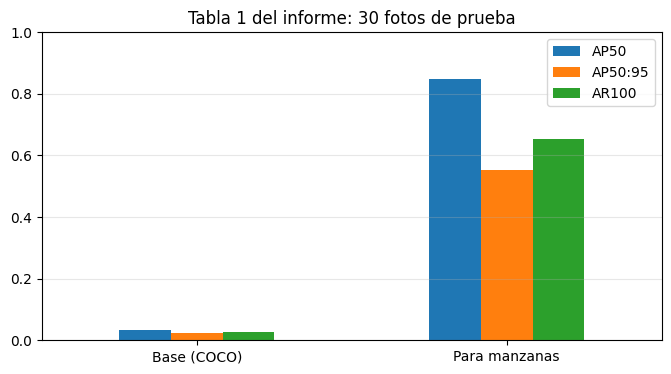

In [ ]:
tabla_1 = pd.DataFrame(medidas_fotos).T
display(tabla_1.round(3))

tabla_1[['AP50', 'AP50:95', 'AR100']].plot.bar(rot=0, figsize=(8, 4), ylim=(0, 1),
                                               title='Tabla 1 del informe: 30 fotos de prueba')
plt.grid(axis='y', alpha=.3)
plt.savefig(salida / 'tabla_1.png', dpi=150)
plt.show()

Figura 5 del informe: las dos fotos de prueba con más manzanas. En cada fila se ve la anotación manual, lo que marca YOLO11n de COCO y lo que marca el detector ajustado, con confianza de 0,35 o más.

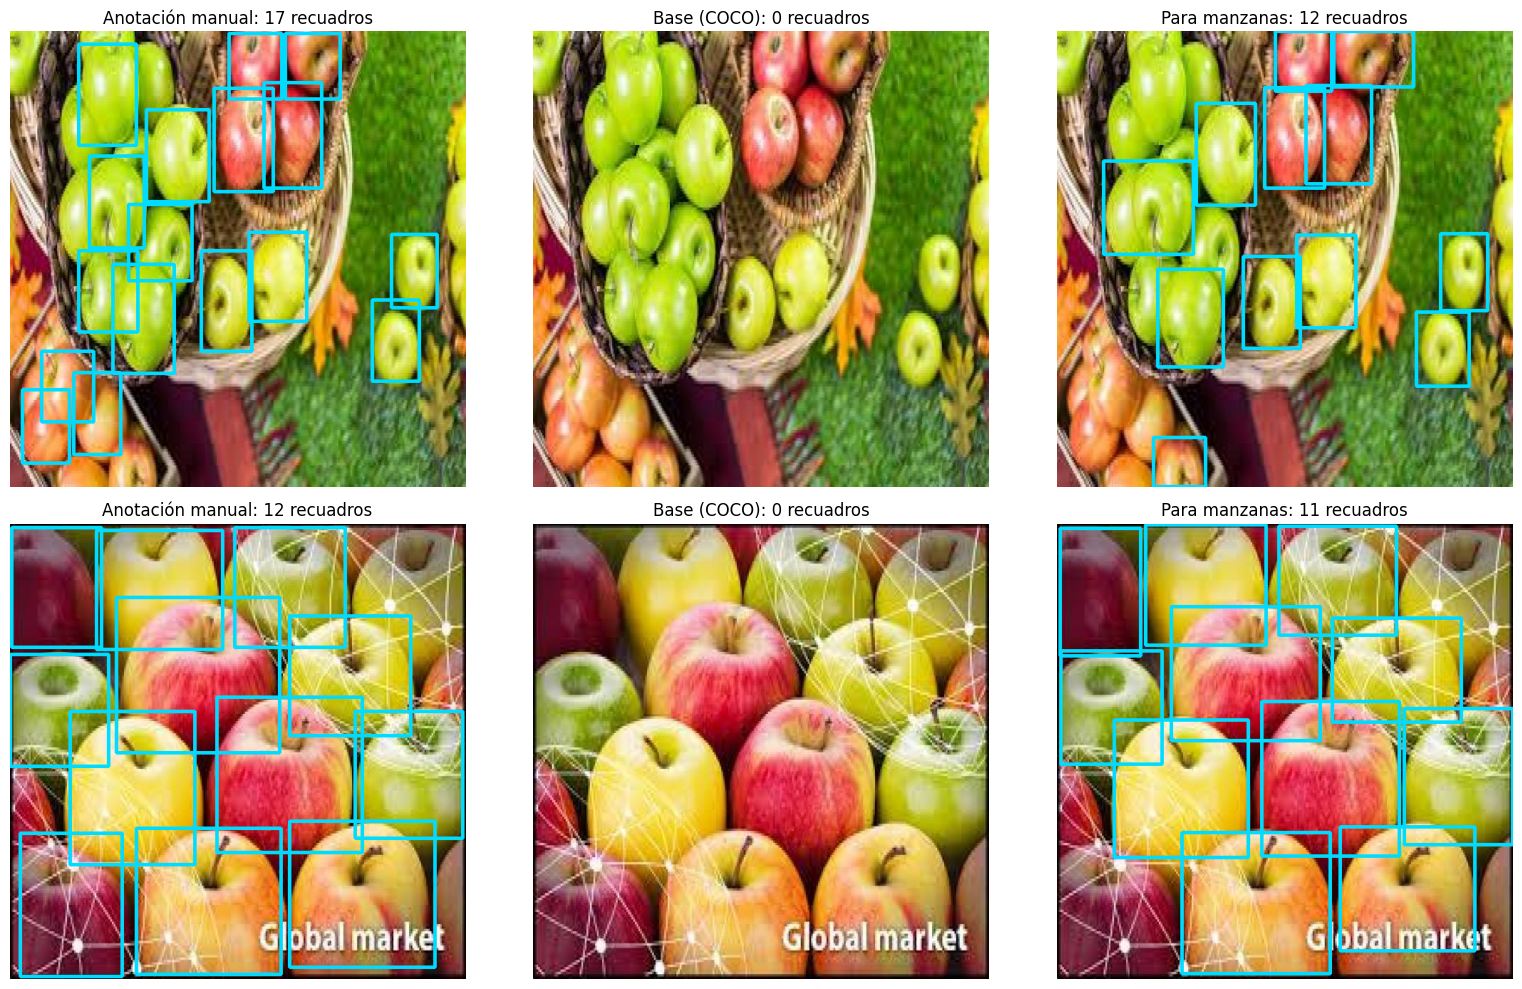

In [ ]:
recuadros = {'Anotación manual': cajas_reales}
for nombre, ruta, clase in [('Base (COCO)', 'yolo11n.pt', 'apple'), ('Para manzanas', pesos['actual'], 'manzana')]:
    recuadros[nombre] = defaultdict(list)
    for deteccion in detectar_fotos(ruta, clase):
        if deteccion['puntaje'] >= 0.35:
            recuadros[nombre][deteccion['foto']].append(deteccion['caja'])

con_mas_manzanas = sorted(cajas_reales, key=lambda numero: len(cajas_reales[numero]), reverse=True)[:2]
figura, ejes = plt.subplots(2, 3, figsize=(16, 10))
for fila, numero in zip(ejes, con_mas_manzanas):
    for eje, (nombre, cajas) in zip(fila, recuadros.items()):
        foto = cv2.cvtColor(cv2.imread(str(fotos_prueba[numero - 1])), cv2.COLOR_BGR2RGB)
        for x1, y1, x2, y2 in cajas[numero]:
            cv2.rectangle(foto, (int(x1), int(y1)), (int(x2), int(y2)), (0, 220, 255), 3)
        eje.imshow(foto)
        eje.set_title(f'{nombre}: {len(cajas[numero])} recuadros')
        eje.axis('off')
plt.tight_layout()
plt.savefig(salida / 'anotacion_base_y_ajustado.png', dpi=150)
plt.show()

## Sección 5.3 del informe: 102 manzanas anotadas en dos cintas

Usamos la configuración de la demo para las cintas: cuadro original, entrada de 1.280 píxeles y confianza mínima de 0,10. Separamos las manzanas cercanas a la cámara de las lejanas.

102 manzanas en 10 cuadros


,manzanas,aciertos,sobrantes,omisiones
zona,,,,
cerca,43,40,4,3
lejos,59,26,13,33


Total: {'manzanas': 102, 'aciertos': 66, 'sobrantes': 17, 'omisiones': 36}


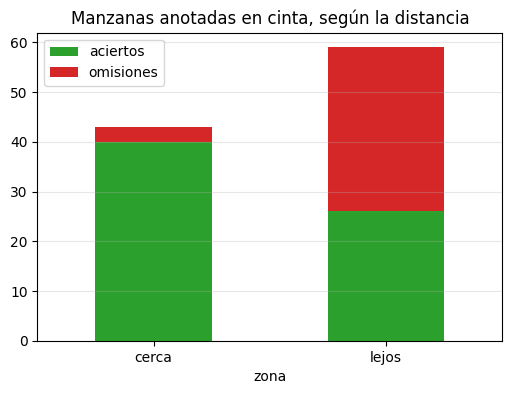

In [ ]:
casos = defaultdict(list)
with (anotaciones / 'cinta_cajas_referencia.csv').open(encoding='utf-8-sig', newline='') as archivo:
    for fila in csv.DictReader(archivo):
        casos[fila['video'], int(fila['cuadro'])].append(fila)


def caja(fila, prefijo=''):
    return tuple(int(fila[prefijo + campo]) for campo in ('x1', 'y1', 'x2', 'y2'))


muestras = {}
for (video, cuadro), filas in sorted(casos.items()):
    captura = cv2.VideoCapture(str(videos / video))
    captura.set(cv2.CAP_PROP_POS_FRAMES, cuadro)
    ok, imagen = captura.read()
    captura.release()
    if not ok:
        raise ValueError(f'No se pudo leer el cuadro {cuadro} de {video}.')
    muestras[video, cuadro] = {
        'video': video, 'zona': filas[0]['zona'], 'imagen': imagen, 'region': caja(filas[0], 'roi_'),
        'reales': [caja(fila) for fila in filas if fila['tipo'] == 'manzana'],
        'ignoradas': [caja(fila) for fila in filas if fila['tipo'] == 'ignorar'],
    }
print(sum(len(muestra['reales']) for muestra in muestras.values()), 'manzanas en', len(muestras), 'cuadros')


def detectar_cinta(yolo, imagen):
    cajas = yolo.predict(imagen, imgsz=1280, conf=0.10, max_det=300, iou=0.7,
                         device=0, verbose=False)[0].boxes.xyxy.cpu().numpy()
    escala = np.array([960 / imagen.shape[1], 540 / imagen.shape[0]] * 2)
    return (cajas * escala).astype(int).tolist()


def medir_cinta(ruta):
    yolo = YOLO(ruta)
    filas = []
    for muestra in muestras.values():
        aciertos, sobrantes, omisiones = contar(muestra['reales'], detectar_cinta(yolo, muestra['imagen']),
                                               muestra['ignoradas'], muestra['region'])
        filas.append({'video': muestra['video'], 'zona': muestra['zona'], 'manzanas': len(muestra['reales']),
                      'aciertos': aciertos, 'sobrantes': sobrantes, 'omisiones': omisiones})
    return pd.DataFrame(filas)


columnas = ['manzanas', 'aciertos', 'sobrantes', 'omisiones']
cintas = {'actual': medir_cinta(pesos['actual'])}
por_zona = cintas['actual'].groupby('zona')[columnas].sum()
display(por_zona)
print('Total:', cintas['actual'][columnas].sum().to_dict())

por_zona[['aciertos', 'omisiones']].plot.bar(stacked=True, rot=0, figsize=(6, 4), color=['tab:green', 'tab:red'],
                                             title='Manzanas anotadas en cinta, según la distancia')
plt.grid(axis='y', alpha=.3)
plt.savefig(salida / 'cinta_cerca_y_lejos.png', dpi=150)
plt.show()

## Figuras 1 y 8 del informe

Los recuadros que dibuja el detector actual en un cuadro de cada cinta.

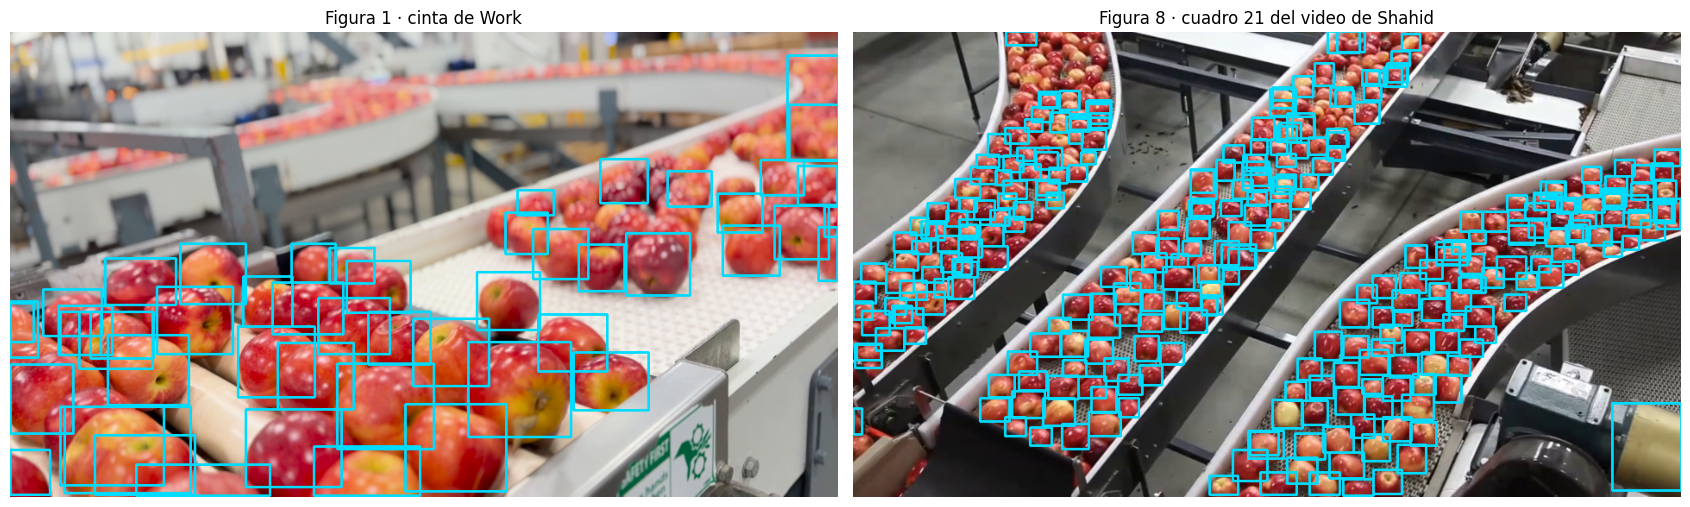

In [ ]:
yolo = YOLO(pesos['actual'])
elegidas = [('manzanas_en_cinta.mp4', 23, 'Figura 1 · cinta de Work'),
            ('cinta_industrial.mp4', 21, 'Figura 8 · cuadro 21 del video de Shahid')]
figura, ejes = plt.subplots(1, 2, figsize=(17, 5))
for eje, (video, cuadro, titulo) in zip(ejes, elegidas):
    imagen = muestras[video, cuadro]['imagen']
    vista = cv2.cvtColor(cv2.resize(imagen, (960, 540)), cv2.COLOR_BGR2RGB)
    for x1, y1, x2, y2 in detectar_cinta(yolo, imagen):
        cv2.rectangle(vista, (x1, y1), (x2, y2), (0, 220, 255), 2)
    eje.imshow(vista)
    eje.set_title(titulo)
    eje.axis('off')
plt.tight_layout()
plt.savefig(salida / 'figuras_1_y_8.png', dpi=150)
plt.show()

## Reentrenar en la A100

Cuatro fotos de entrenamiento con sus recuadros, para ver qué tamaño de manzana aprende el detector.

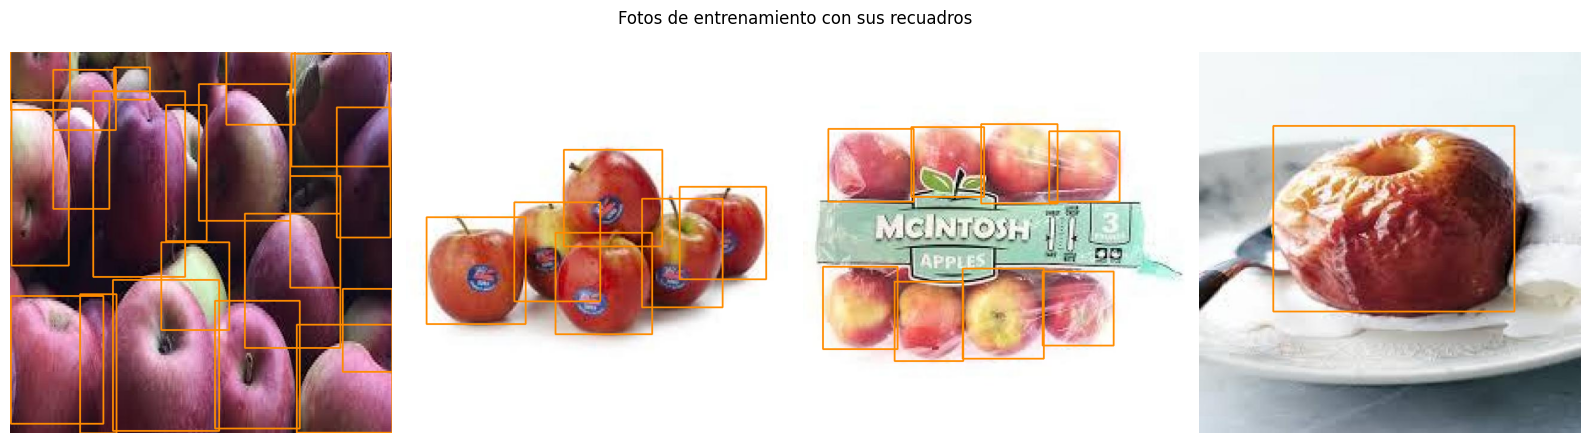

In [ ]:
figura, ejes = plt.subplots(1, 4, figsize=(16, 4.5))
for eje, nombre in zip(ejes, particiones['train'][:4]):
    foto = cv2.cvtColor(cv2.imread(str(datos / 'train' / 'images' / nombre)), cv2.COLOR_BGR2RGB)
    alto, ancho = foto.shape[:2]
    etiqueta = datos / 'train' / 'labels' / (Path(nombre).stem + '.txt')
    for linea in etiqueta.read_text().splitlines():
        _, x, y, w, h = [float(valor) for valor in linea.split()]
        cv2.rectangle(foto, (int((x - w / 2) * ancho), int((y - h / 2) * alto)),
                      (int((x + w / 2) * ancho), int((y + h / 2) * alto)), (255, 140, 0), 2)
    eje.imshow(foto)
    eje.axis('off')
figura.suptitle('Fotos de entrenamiento con sus recuadros')
plt.tight_layout()
plt.show()

Las dos corridas parten de YOLO11n preentrenado en COCO y usan la misma semilla. `base` usa los aumentos habituales y `escala` achica más las fotos, para que el detector vea manzanas pequeñas como las de la cinta. Ultralytics guarda en `best.pt` la mejor época de validación.

In [ ]:
variantes = {'base': {}, 'escala': {'scale': 0.9}}

for nombre, cambios in variantes.items():
    modelo = YOLO('yolo11n.pt')
    modelo.train(data=str(data_yaml), epochs=100, patience=20, imgsz=640, batch=32, seed=0,
                 optimizer='AdamW', lr0=0.002, device=0, workers=8, plots=False,
                 project=str(trabajo / 'corridas'), name=nombre, exist_ok=True, **cambios)
    corrida = Path(modelo.trainer.save_dir)
    (salida / nombre).mkdir()
    shutil.copy2(corrida / 'weights' / 'best.pt', salida / nombre / 'best.pt')
    shutil.copy2(corrida / 'results.csv', salida / nombre / 'results.csv')
    pesos[nombre] = salida / nombre / 'best.pt'
    print(nombre, 'guardado en', salida / nombre)

Las curvas muestran cómo avanzó cada corrida en la validación.

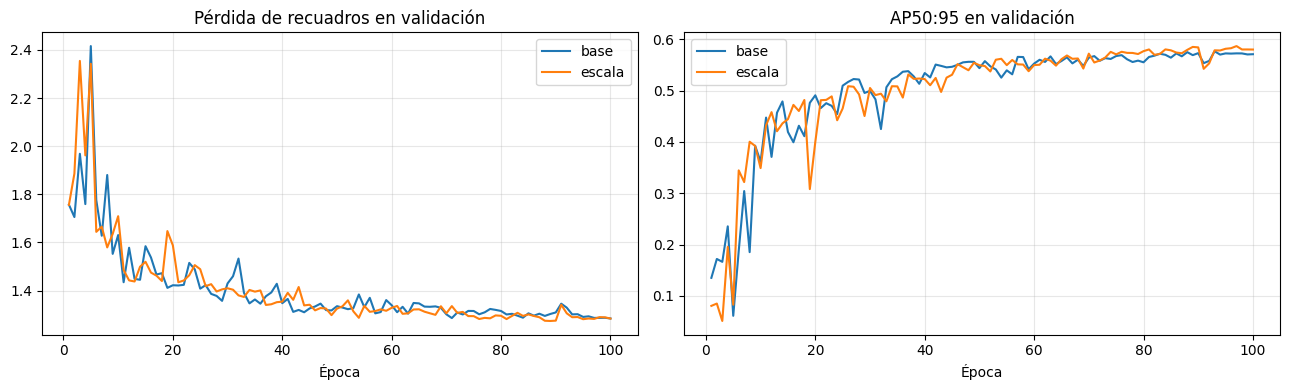

In [ ]:
figura, ejes = plt.subplots(1, 2, figsize=(13, 4))
for nombre in variantes:
    curva = pd.read_csv(salida / nombre / 'results.csv')
    curva.columns = curva.columns.str.strip()
    ejes[0].plot(curva['epoch'], curva['val/box_loss'], label=nombre)
    ejes[1].plot(curva['epoch'], curva['metrics/mAP50-95(B)'], label=nombre)
ejes[0].set_title('Pérdida de recuadros en validación')
ejes[1].set_title('AP50:95 en validación')
for eje in ejes:
    eje.set_xlabel('Época')
    eje.grid(alpha=.3)
    eje.legend()
plt.tight_layout()
plt.savefig(salida / 'curvas.png', dpi=150)
plt.show()

## Comparar en las cintas y elegir

Medimos los detectores nuevos en las mismas 102 manzanas y aplicamos el criterio fijado al principio.

,actual,base,escala
aciertos,66,48,62
sobrantes,17,11,13
omisiones,36,54,40


,actual,base,escala
zona,,,
cerca,40,34,36
lejos,26,14,26


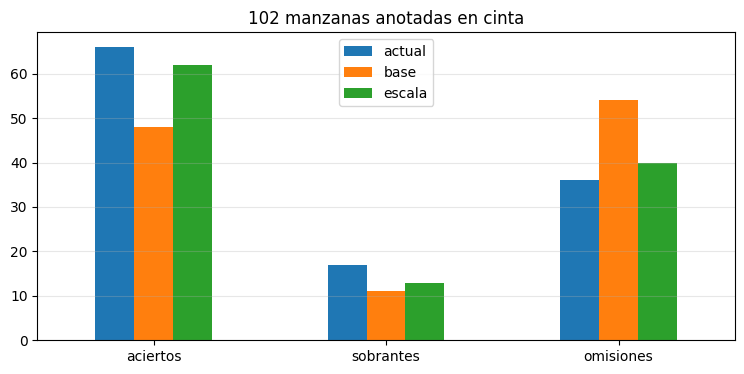

Detector elegido: actual


In [ ]:
for nombre in variantes:
    cintas[nombre] = medir_cinta(pesos[nombre])

totales = pd.DataFrame({nombre: tabla[['aciertos', 'sobrantes', 'omisiones']].sum()
                        for nombre, tabla in cintas.items()})
cercanas = pd.DataFrame({nombre: tabla.groupby('zona')['aciertos'].sum() for nombre, tabla in cintas.items()})
display(totales)
display(cercanas)

totales.plot.bar(rot=0, figsize=(9, 4), title='102 manzanas anotadas en cinta')
plt.grid(axis='y', alpha=.3)
plt.savefig(salida / 'cinta_102_manzanas.png', dpi=150)
plt.show()

elegido = 'actual'
for nombre in variantes:
    mas_aciertos = totales[nombre]['aciertos'] > totales[elegido]['aciertos']
    sin_mas_sobrantes = totales[nombre]['sobrantes'] <= totales['actual']['sobrantes']
    if mas_aciertos and sin_mas_sobrantes:
        elegido = nombre
print('Detector elegido:', elegido)

Un cuadro de cada cinta con los recuadros de cada detector. En blanco van las manzanas anotadas a mano y en naranja las que propone el detector.

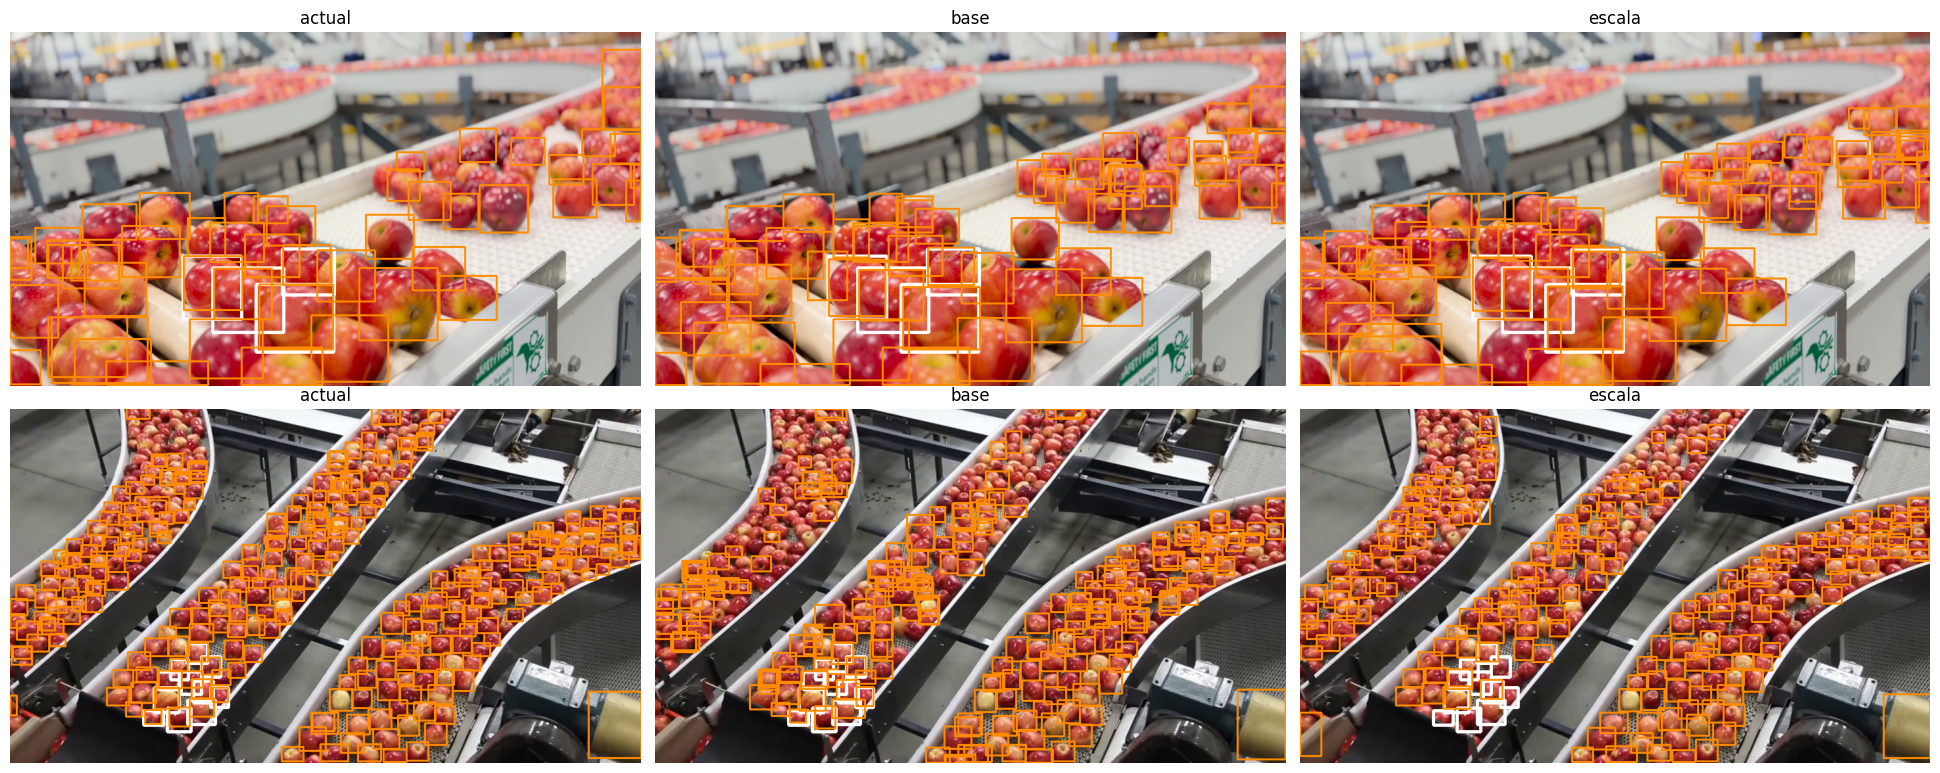

In [ ]:
ejemplos = [muestras['manzanas_en_cinta.mp4', 23], muestras['cinta_industrial.mp4', 21]]
figura, ejes = plt.subplots(len(ejemplos), len(pesos), figsize=(6.5 * len(pesos), 3.9 * len(ejemplos)))
for fila, muestra in zip(ejes, ejemplos):
    for eje, (nombre, ruta) in zip(fila, pesos.items()):
        vista = cv2.cvtColor(cv2.resize(muestra['imagen'], (960, 540)), cv2.COLOR_BGR2RGB)
        for x1, y1, x2, y2 in muestra['reales']:
            cv2.rectangle(vista, (x1, y1), (x2, y2), (255, 255, 255), 3)
        for x1, y1, x2, y2 in detectar_cinta(YOLO(ruta), muestra['imagen']):
            cv2.rectangle(vista, (x1, y1), (x2, y2), (255, 140, 0), 2)
        eje.imshow(vista)
        eje.set_title(nombre)
        eje.axis('off')
plt.tight_layout()
plt.savefig(salida / 'cinta_ejemplos.png', dpi=150)
plt.show()

## Medir después de elegir

Recién ahora miramos las 30 fotos de prueba con los detectores nuevos. También contamos los 24 cruces anotados de un segundo video de Work, que no se usó para elegir la configuración.

In [ ]:
from evaluacion_cinta import evaluar

for nombre in variantes:
    medidas_fotos[nombre] = medir_fotos(pesos[nombre], 'manzana')

destino = salida / 'segunda_cinta'
evaluar(videos / 'seleccion_manzanas.mp4', anotaciones / 'seleccion_cruces_referencia.json',
        YOLO(pesos[elegido]), pesos[elegido], 0, destino)
medidas = json.loads((destino / 'evaluacion.json').read_text())
segunda_cinta = {'cruces anotados': medidas['referencia'], 'emparejados': medidas['coincidencias'],
                 'omitidos': medidas['omitidos'], 'sobrantes': medidas['sin_referencia']}
print('Segundo video de Work con el detector', elegido, segunda_cinta)

Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.13s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.631
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.925
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.740
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.279
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.665
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.158
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.634
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.697
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

## Resumen

,AP50,AP50:95,AR100,"Encontradas con confianza 0,35",Recuadros sin coincidencia
Base (COCO),0.033,0.024,0.026,2.0,0.0
Para manzanas,0.848,0.553,0.655,113.0,8.0
base,0.925,0.631,0.697,133.0,15.0
escala,0.942,0.646,0.713,135.0,17.0


,actual,base,escala
aciertos,66,48,62
sobrantes,17,11,13
omisiones,36,54,40


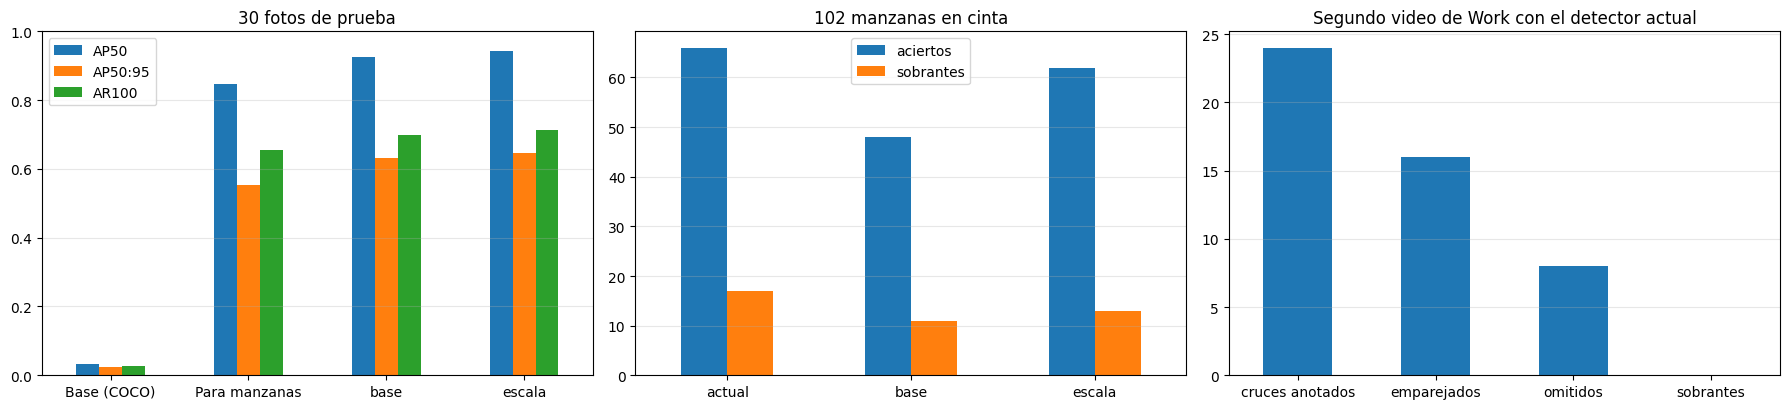

Detector elegido: actual


In [ ]:
tabla_fotos = pd.DataFrame(medidas_fotos).T
display(tabla_fotos.round(3))
display(totales)

figura, ejes = plt.subplots(1, 3, figsize=(18, 4.2))
tabla_fotos[['AP50', 'AP50:95', 'AR100']].plot.bar(ax=ejes[0], rot=0, ylim=(0, 1), title='30 fotos de prueba')
totales.T[['aciertos', 'sobrantes']].plot.bar(ax=ejes[1], rot=0, title='102 manzanas en cinta')
pd.Series(segunda_cinta).plot.bar(ax=ejes[2], rot=0, color='tab:blue',
                                  title=f'Segundo video de Work con el detector {elegido}')
for eje in ejes:
    eje.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.savefig(salida / 'resumen.png', dpi=150)
plt.show()

resumen = {'elegido': elegido, 'gpu': torch.cuda.get_device_name(0), 'fotos_de_prueba': medidas_fotos,
           'cintas': totales.to_dict(), 'cintas_por_zona_actual': por_zona.to_dict(),
           'segunda_cinta': segunda_cinta}
(salida / 'resumen.json').write_text(json.dumps(resumen, indent=2, ensure_ascii=False))
print('Detector elegido:', elegido)